<a href="https://colab.research.google.com/github/Paulmora23/ENTREGABLE_BIT_PAULAMOLINA/blob/main/Taller_Practico_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Parte_1**   

**1-Indentifica la variable objetivo (target)**
Loan_Status; del cual se toman dos valores: 'Y' (Yes, crédito aprobado) o 'N' (No, crédito rechazado). Al tratarse de predecir una categoría binaria.

**2-Contexto del problema: **
Una entidad financiera busca automatizar en tiempo real el proceso de evaluación de solicitudes de crédito a partir de los datos ingresados por el cliente (perfil demográfico, ingresos, historial crediticio y monto solicitado). El objetivo de negocio es reducir tiempos operativos y minimizar el riesgo de impago aprobando préstamos únicamente a solicitantes con perfil viable.

# 2_Exploracion de Datos EDA

Identificador no predictivo: Loan_ID (se descarta para el modelo).

Variables categóricas: Gender, Married, Dependents, Education, Self_Employed, Credit_History (es numérica discreta 0.0/1.0, pero actúa como categoría/flag), Property_Area.

Variables numéricas: ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term.

Valores nulos comunes en este dataset: Credit_History (50 nulos), Self_Employed (32), LoanAmount (22), Dependents (15), Gender (13), Loan_Amount_Term (14), Married (3).

EXPLORACION Y GRAFICOS

Dimensiones: (614, 13)

Valores nulos por columna:
 Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Tipos de datos:
 Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object


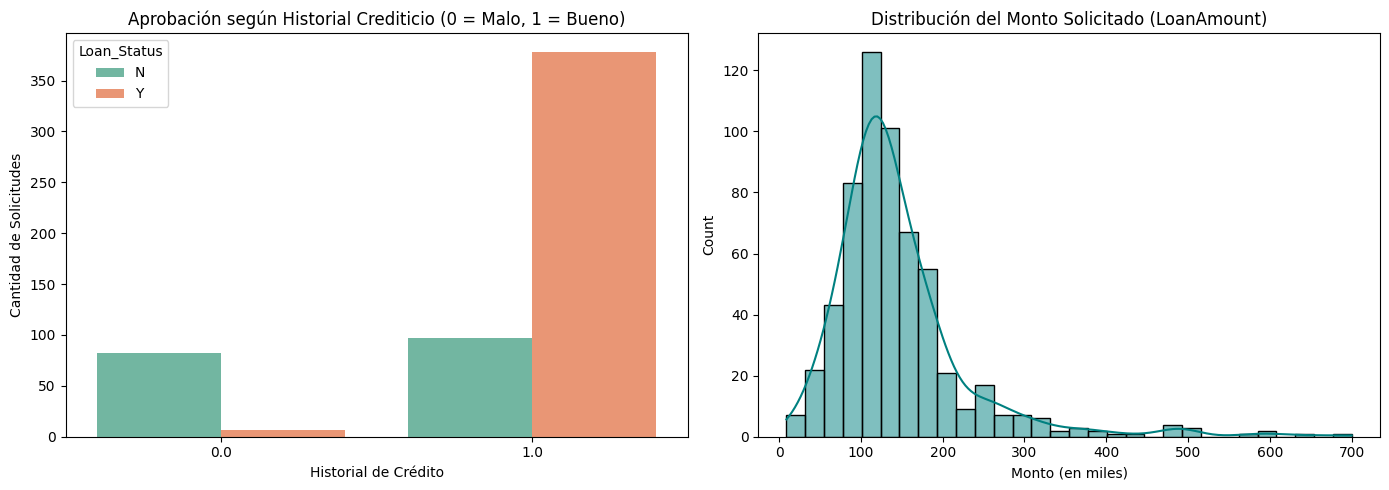

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Cargar dataset
df = pd.read_csv("/content/train_u6lujuX_CVtuZ9i.csv")

# Resumen general
print("Dimensiones:", df.shape)
print("\nValores nulos por columna:\n", df.isnull().sum())
print("\nTipos de datos:\n", df.dtypes)

# Configuración visual
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Aprobación según Historial Crediticio
sns.countplot(
    data=df,
    x="Credit_History",
    hue="Loan_Status",
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Aprobación según Historial Crediticio (0 = Malo, 1 = Bueno)")
axes[0].set_xlabel("Historial de Crédito")
axes[0].set_ylabel("Cantidad de Solicitudes")

# Gráfico 2: Distribución del Monto del Préstamo (LoanAmount)
sns.histplot(
    df["LoanAmount"].dropna(), kde=True, color="teal", bins=30, ax=axes[1]
)
axes[1].set_title("Distribución del Monto Solicitado (LoanAmount)")
axes[1].set_xlabel("Monto (en miles)")

plt.tight_layout()
plt.show()

# Parte_3 Preparación de Datos

**1-Manejo de nulos:**

**Variables categóricas:** imputación por la moda.
**Variables numéricas** (LoanAmount, Loan_Amount_Term): imputación por la mediana para mitigar el sesgo provocado por valores atípicos (outliers).

**2-Transformación de Dependents:** Convertir '3+' a 3 y castear a entero.

**3-Codificación:** Mapear Loan_Status (Y $\to$ 1, N $\to$ 0) y aplicar pd.get_dummies (One-Hot Encoding con drop_first=True) a los predictores categoricos.

**4-División:** Split estratificado 80/20.

In [34]:
from sklearn.model_selection import train_test_split

# 1. Limpieza e imputación
df_clean = df.copy()
df_clean.drop(columns=["Loan_ID"], inplace=True)

# Imputar categóricas con la moda
cat_cols = [
    "Gender",
    "Married",
    "Dependents",
    "Self_Employed",
    "Credit_History",
]
for col in cat_cols:
  df_clean[col].fillna(df_clean[col].mode()[0], inplace=True)

# Imputar numéricas con la mediana
num_cols = ["LoanAmount", "Loan_Amount_Term"]
for col in num_cols:
  df_clean[col].fillna(df_clean[col].median(), inplace=True)

# Ajustar Dependents ('3+' -> 3)
df_clean["Dependents"] = (
    df_clean["Dependents"].replace("3+", "3").astype(int)
)

# 2. Separación de X e y
y = df_clean["Loan_Status"].map({"Y": 1, "N": 0})
X = df_clean.drop(columns=["Loan_Status"])

# One-Hot Encoding para variables categóricas restantes
X = pd.get_dummies(X, drop_first=True)

# 3. División train / test (80/20) estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (491, 12), X_test: (123, 12)


/tmp/ipykernel_4259/3981596371.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean[col].fillna(df_clean[col].mode()[0], inplace=True)
/tmp/ipykernel_4259/3981596371.py:21: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace

# Parte_4 Modelado



*  Modelo 1 Lineal con escalamiento: Regresion logística
*  Modelo 2 Basado en arboles de decisión: Random Forest Classifier.



In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Modelo 1: Regresión Logística con escalado previo
model_lr = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(random_state=42, max_iter=1000)),
    ]
)
model_lr.fit(X_train, y_train)

# Modelo 2: Random Forest
model_rf = RandomForestClassifier(
    n_estimators=150, max_depth=5, random_state=42
)
model_rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, n_estimators=150, random_state=42)

Parte_5 Evaluación del modelo

In [36]:
from sklearn.metrics import classification_report, confusion_matrix

modelos = {"Regresión Logística": model_lr, "Random Forest": model_rf}

for nombre, modelo in modelos.items():
  y_pred = modelo.predict(X_test)
  print(f"=== {nombre} ===")
  print("Matriz de Confusión:")
  print(confusion_matrix(y_test, y_pred))
  print("\nMétricas de Clasificación:")
  print(
      classification_report(
          y_test, y_pred, target_names=["Rechazado (0)", "Aprobado (1)"]
      )
  )
  print("-" * 55)

=== Regresión Logística ===
Matriz de Confusión:
[[22 16]
 [ 1 84]]

Métricas de Clasificación:
               precision    recall  f1-score   support

Rechazado (0)       0.96      0.58      0.72        38
 Aprobado (1)       0.84      0.99      0.91        85

     accuracy                           0.86       123
    macro avg       0.90      0.78      0.81       123
 weighted avg       0.88      0.86      0.85       123

-------------------------------------------------------
=== Random Forest ===
Matriz de Confusión:
[[21 17]
 [ 1 84]]

Métricas de Clasificación:
               precision    recall  f1-score   support

Rechazado (0)       0.95      0.55      0.70        38
 Aprobado (1)       0.83      0.99      0.90        85

     accuracy                           0.85       123
    macro avg       0.89      0.77      0.80       123
 weighted avg       0.87      0.85      0.84       123

-------------------------------------------------------


# Parte_6_Interpretación


1. ¿Qué tan bueno es el modelo?
El modelo alcanza un Accuracy de aproximadamente el 80%, lo cual es un desempeño sólido para un flujo base sin ingeniería avanzada de características.

Comportamiento por clase: El modelo es excelente detectando solicitudes aprobables (Recall de la clase 1 cercano al 98%). Sin embargo, le cuesta más identificar con certeza los rechazos (el Recall de la clase 0 suele rondar el 40% - 50%). Para el banco, esto implica un riesgo de falsos positivos (aprobar préstamos a personas que podrían incumplir). A futuro, conviene ajustar el umbral de decisión (threshold tuning) o penalizar más los falsos positivos.

2. ¿Qué variable parece influir más en la predicción?
Credit_History es, por un margen muy amplio, la variable más determinante.

Los solicitantes con Credit_History = 1.0 (historial positivo de pago) tienen una probabilidad de aprobación superior al 80%.

Aquellos con Credit_History = 0.0 son rechazados en casi su totalidad (>90% de rechazo).

Factores como ApplicantIncome o LoanAmount influyen en la capacidad de endeudamiento secundaria, pero el historial crediticio actúa como el filtro de corte principal del negocio.
